A fluid occupies the slit pore between two vertical walls. Each wall is maintained at a uniform temperature, such that the temperature varies linearly across the pore

$$
T(x) = \overline T + \frac{x}{d} \left( \frac{T_2 - T_1}{2}\right)
$$

where
the pore has width of 2$d$,
the temperature $T_1$ ($T_2$) is the uniform temperature of the left (right) wall,
and
$\overline T$ is the mean temprature at the centerline of the pore.

The density varies with temperature 

$$
\rho(T) = \overline \rho \left[ 1 - \beta(T-\overline T)\right]
$$

where
$\overline \rho$ is the density at the mean temperature
and
$\beta$ is the volume coefficient of expansion. The density gradient induces natural convection.

The governing equation for the velocity profile is 

$$
\mu \frac{d^2 v_y}{dx^2} + g \overline \rho -g \rho(T) = 0
$$

with no slip boundary conditions

$$
v_y(-d) = v_y(d) = 0
$$

Solve for the velocity profile for a 1-cm wide slit pore filled with water. The left and right walls are maintained at 58 and 62°C, respectively. The relevant properties of water at 60°C are:

> $\overline \rho$ = 984.4 kg/m$^3$  
> $\mu$ = 0.467 cp  
> $\beta$ = 5.22 $\cdot$ 10$^{-4}$ / K

Text(0, 0.5, 'Velocity, $m/s$')

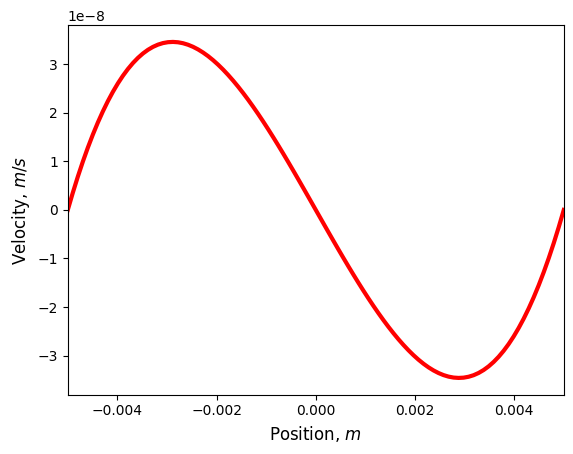

In [34]:
import numpy as np
import matplotlib.pyplot as plt
import scipy.optimize as opt

## internal units ##
# length: m
# temperature: K
# mass: kg
# time: seconds

# conversion

cm_to_m = 0.01
cp_to_poise = 1000
c_to_k = 273.15 

# boundary conditions
width = 1 # cm
d = width*cm_to_m/2  # m
vd = vnegd = 0 # no split boundary condition

# properties of water at 60 C
B = 5.22e-4  # 1/K
rho_bar = 984.4 #kg/m^3
U = 0.467*cp_to_poise  #Pa*s = kg/(m*s) 

# gravity
g = -9.8 #m/s^2 include negative sign for directionality 

# Temperature parameters
T1 = 58+c_to_k # kevlin
T2 = 62+c_to_k # kelvin
T_bar = 60+c_to_k

# finite difference parameters 
N = 100 # number of points, resolution N/L 
x = np.linspace(-d,d,N)

dx = x[1]-x[0]
dx2 = dx*dx

def ode(v,dx2): # v, velocity at every point where interested in, return all residual
    res = np.zeros_like(v)

    # left boundary 
    res[0] = v[0]-vnegd
    
    # interior 
    for i in range(1,N-1):

        T = T_bar + (x[i]/d)*((T2-T1)/2) 
        rho = rho_bar*(1-B*(T-T_bar))

        d2v = (v[i+1]-2*v[i]+v[i-1])
        res[i] = U*d2v/dx2 + g*rho_bar - g*rho

    # right boundary 
    res[-1]=v[-1]-vd
    return res

sol = opt.root(ode,np.ones(N),args=(dx2,))
v = sol.x

plt.plot(x,v,lw=3,color='r')
plt.xlabel('Position, $m$', fontsize = 12)
plt.xlim(-d,d)
plt.ylabel('Velocity, $m/s$', fontsize = 12)